<a href="https://colab.research.google.com/github/saisudhanv/ML-Practice/blob/main/Bagging.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv('/content/IRIS.csv')

In [3]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [4]:
from sklearn.preprocessing import LabelEncoder

In [5]:
encoder = LabelEncoder()

In [6]:
df['species'] = encoder.fit_transform(df['species'])

In [7]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [9]:
df = df[df['species'] != 0][['sepal_width','petal_length','species']]

In [10]:
df.head()

,sepal_width,petal_length,species
50,3.2,4.7,1
51,3.2,4.5,1
52,3.1,4.9,1
53,2.3,4.0,1
54,2.8,4.6,1


In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

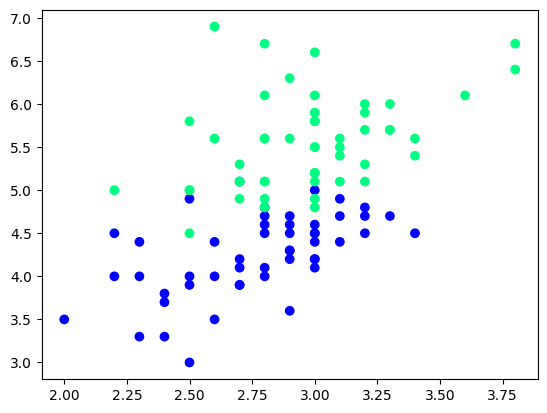

In [12]:
plt.scatter(df['sepal_width'], df['petal_length'], c = df['species'], cmap = 'winter')

In [13]:
df_train = df.iloc[:60, :].sample(10)
df_train

,sepal_width,petal_length,species
100,3.3,6.0,2
70,3.2,4.8,1
77,3.0,5.0,1
71,2.8,4.0,1
51,3.2,4.5,1
74,2.9,4.3,1
99,2.8,4.1,1
54,2.8,4.6,1
76,2.8,4.8,1
90,2.6,4.4,1


In [14]:
# Taking only 10 rows for training
df = df.sample(100)
df_train = df.iloc[:60,:].sample(10)
df_val = df.iloc[60:80,:].sample(5)
df_test = df.iloc[80:,:].sample(5)

In [15]:
df_train

,sepal_width,petal_length,species
132,2.8,5.6,2
91,3.0,4.6,1
76,2.8,4.8,1
98,2.5,3.0,1
138,3.0,4.8,2
57,2.4,3.3,1
103,2.9,5.6,2
141,3.1,5.1,2
74,2.9,4.3,1
60,2.0,3.5,1


In [16]:
df_val

,sepal_width,petal_length,species
82,2.7,3.9,1
79,2.6,3.5,1
147,3.0,5.2,2
50,3.2,4.7,1
69,2.5,3.9,1


In [17]:
df_test

,sepal_width,petal_length,species
145,3.0,5.2,2
87,2.3,4.4,1
63,2.9,4.7,1
68,2.2,4.5,1
142,2.7,5.1,2


In [18]:
X_test = df_val.iloc[:, 0:2].values
y_test = df_val.iloc[:, -1].values

In [19]:
y_test

array([1, 1, 2, 1, 1])

**Case 1 - Bagging**

In [20]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

df_bag

,sepal_width,petal_length,species
57,2.4,3.3,1
141,3.1,5.1,2
98,2.5,3.0,1
98,2.5,3.0,1
57,2.4,3.3,1
132,2.8,5.6,2
132,2.8,5.6,2
138,3.0,4.8,2


In [21]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from mlxtend.plotting import plot_decision_regions
from sklearn.metrics import accuracy_score

In [22]:
dt_bag1 = DecisionTreeClassifier()

In [30]:
def evaluate(clf,X,y):
    clf.fit(X,y)
    plot_tree(clf)
    plt.show()
    plot_decision_regions(X.values, y.values, clf=clf, legend=2)
    y_pred = clf.predict(X_test)
    print(accuracy_score(y_test,y_pred))

In [31]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,sepal_width,petal_length,species
74,2.9,4.3,1
103,2.9,5.6,2
138,3.0,4.8,2
76,2.8,4.8,1
74,2.9,4.3,1
98,2.5,3.0,1
91,3.0,4.6,1
132,2.8,5.6,2


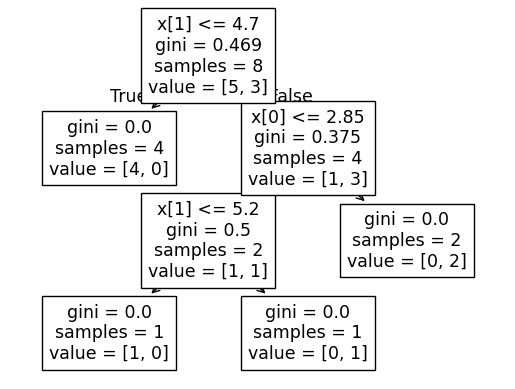

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


1.0


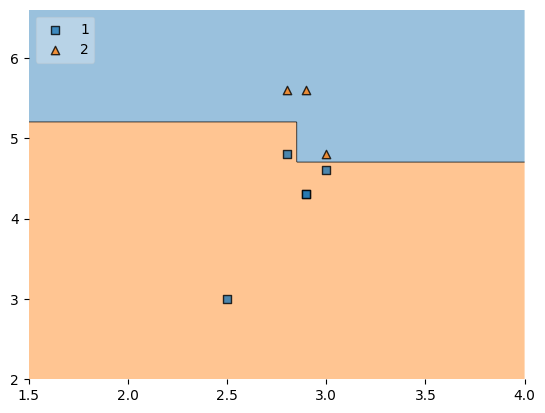

In [32]:
dt_bag2 = DecisionTreeClassifier()
evaluate(dt_bag2,X,y)

In [33]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,sepal_width,petal_length,species
91,3.0,4.6,1
98,2.5,3.0,1
60,2.0,3.5,1
91,3.0,4.6,1
74,2.9,4.3,1
60,2.0,3.5,1
141,3.1,5.1,2
141,3.1,5.1,2


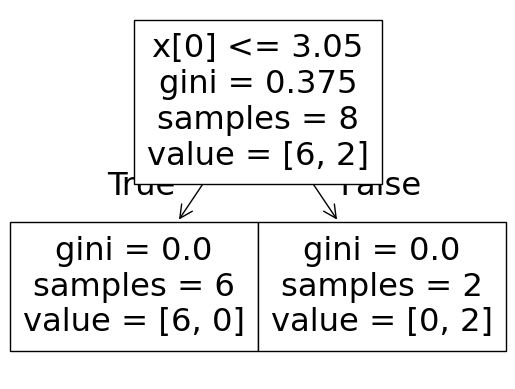

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


0.6


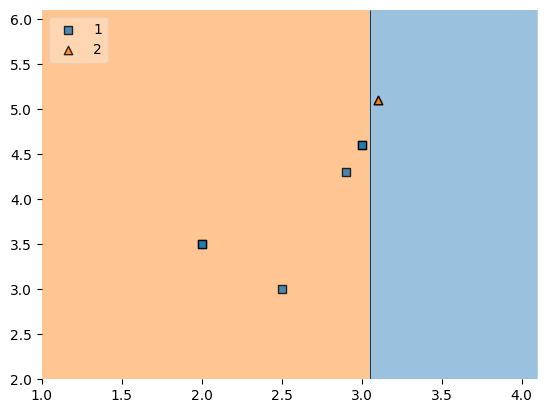

In [34]:
dt_bag3 = DecisionTreeClassifier()
evaluate(dt_bag3,X,y)

**Predict**

In [35]:
df_test

,sepal_width,petal_length,species
145,3.0,5.2,2
87,2.3,4.4,1
63,2.9,4.7,1
68,2.2,4.5,1
142,2.7,5.1,2


In [36]:
print("Predictor 1",dt_bag1.predict(np.array([2.2,5.0]).reshape(1,2)))
print("Predictor 2",dt_bag2.predict(np.array([2.2,5.0]).reshape(1,2)))
print("Predictor 3",dt_bag3.predict(np.array([2.2,5.0]).reshape(1,2)))

Predictor 1 [2]
Predictor 2 [1]
Predictor 3 [1]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


**Pasting**

In [37]:
# Row sampling without replacement
df_train

,sepal_width,petal_length,species
132,2.8,5.6,2
91,3.0,4.6,1
76,2.8,4.8,1
98,2.5,3.0,1
138,3.0,4.8,2
57,2.4,3.3,1
103,2.9,5.6,2
141,3.1,5.1,2
74,2.9,4.3,1
60,2.0,3.5,1


In [38]:
df_train.sample(8)

,sepal_width,petal_length,species
103,2.9,5.6,2
60,2.0,3.5,1
57,2.4,3.3,1
76,2.8,4.8,1
98,2.5,3.0,1
141,3.1,5.1,2
138,3.0,4.8,2
132,2.8,5.6,2


**Random Subspaces**

In [39]:
df1 = pd.read_csv('/content/IRIS.csv')

In [40]:
df1.sample(10)

,sepal_length,sepal_width,petal_length,petal_width,species
20,5.4,3.4,1.7,0.2,Iris-setosa
77,6.7,3.0,5.0,1.7,Iris-versicolor
0,5.1,3.5,1.4,0.2,Iris-setosa
90,5.5,2.6,4.4,1.2,Iris-versicolor
23,5.1,3.3,1.7,0.5,Iris-setosa
131,7.9,3.8,6.4,2.0,Iris-virginica
73,6.1,2.8,4.7,1.2,Iris-versicolor
64,5.6,2.9,3.6,1.3,Iris-versicolor
37,4.9,3.1,1.5,0.1,Iris-setosa
133,6.3,2.8,5.1,1.5,Iris-virginica


In [46]:
df1.sample(2, replace=True, axis = 1)

,petal_width,species
0,0.2,Iris-setosa
1,0.2,Iris-setosa
2,0.2,Iris-setosa
3,0.2,Iris-setosa
4,0.2,Iris-setosa
...,...,...
145,2.3,Iris-virginica
146,1.9,Iris-virginica
147,2.0,Iris-virginica
148,2.3,Iris-virginica


**Random Patches**

In [47]:
df1

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


In [48]:
df1.sample(8, replace = True).sample(2, replace = True, axis = 1)

,sepal_width,sepal_width
62,2.2,2.2
65,3.1,3.1
41,2.3,2.3
84,3.0,3.0
82,2.7,2.7
103,2.9,2.9
85,3.4,3.4
112,3.0,3.0
